# Supporting Figure S6

![Full Figure](../figures/suppS6_FULL.png)

## Code for Supporting Figure S6: within-session structure of violations


| Panel | Content |
|---|---|
| a | Violation rate across session progress (10 bins; all trials) |
| b | Violation rate aligned to session start (first 20 trials) |
| c | Violation rate aligned to session end (last 20 trials) |
| d | Full vs. edge-trimmed session autocorrelation (lags 1–20) |

**Outputs:** `figures/suppS6a_session_progress.png`, `figures/suppS6b_session_start.png`, `figures/suppS6c_session_end.png`, `figures/suppS6d_autocorrelation_robustness.png`.


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from violations_glm.config import VIOLATION_COLOR
from violations_glm.io import (
    load_autocorrelation_summary,
    load_history_robustness,
    load_session_edge_rates,
    load_session_position_statistics,
    load_session_progress_violation_rates,
)
from violations_glm.plotting import configure_publication_dpi, save_figure

configure_publication_dpi()

sns.set_context(
    "notebook",
    rc={
        "font.size": 20,
        "axes.titlesize": 18,
        "axes.labelsize": 18,
        "axes.titleweight": "bold",
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
    },
)

In [3]:
progress_rates = load_session_progress_violation_rates(include_edges=True)
position_statistics = load_session_position_statistics()
edge_rates = load_session_edge_rates()
animal_grays = ["gray"] * progress_rates["animal_id"].nunique()

# Plot each bin at its upper edge, so 10 marks the first 10% of session trials.
progress_rates["progress_edge"] = (progress_rates["progress_bin"] + 1) * 10

## Panel A — Violation rate across session progress

Ten equal trial fractions per session using all trials, each plotted at the upper edge of its bin (10 = first 10% of session trials). Gray lines: individual animals; colored line: mean ± SEM.


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS6a_session_progress.png')

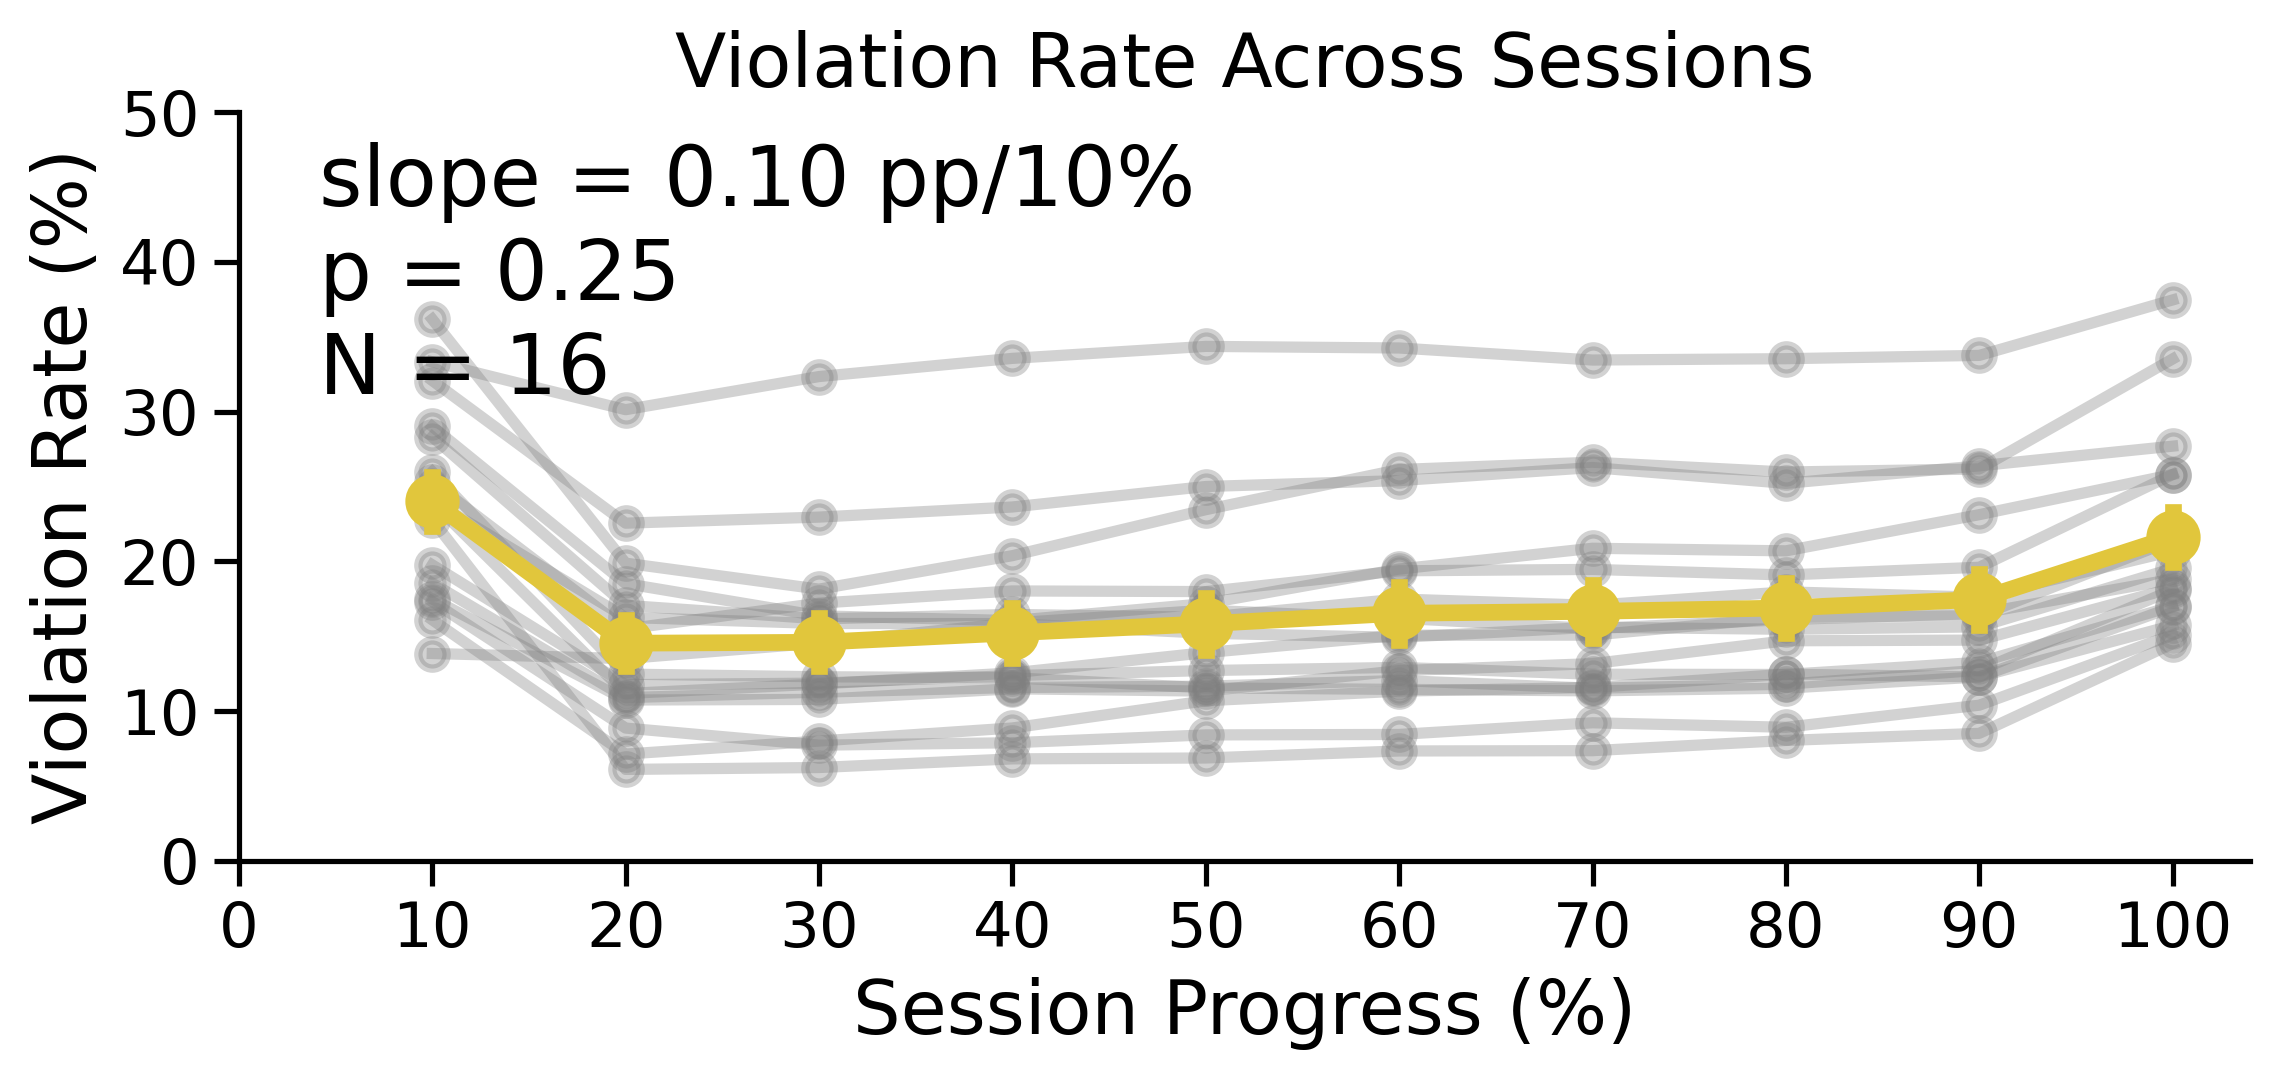

In [4]:
all_stats = position_statistics["all_trials"]["slope_per_10_percent"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.pointplot(
    data=progress_rates,
    x="progress_edge",
    y="viol_rate",
    hue="animal_id",
    palette=animal_grays,
    alpha=0.35,
    native_scale=True,
    legend=False,
    ax=ax,
)
sns.pointplot(
    data=progress_rates,
    x="progress_edge",
    y="viol_rate",
    color=VIOLATION_COLOR,
    errorbar="se",
    linewidth=4,
    native_scale=True,
    ax=ax,
)
ax.text(
    0.04,
    0.96,
    f"slope = {all_stats['mean_slope']:.2f} pp/10%\n"
    f"p = {all_stats['p_value']:.2g}\n"
    f"N = {all_stats['n_animals']}",
    transform=ax.transAxes,
    va="top",
)
ax.set(
    xticks=range(0, 101, 10),
    xlim=(0, 104),
    xlabel="Session Progress (%)",
    ylabel="Violation Rate (%)",
    title="Violation Rate Across Sessions",
    ylim=(0, 50),
)
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "suppS6a_session_progress")

## Panel B — Session start


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS6b_session_start.png')

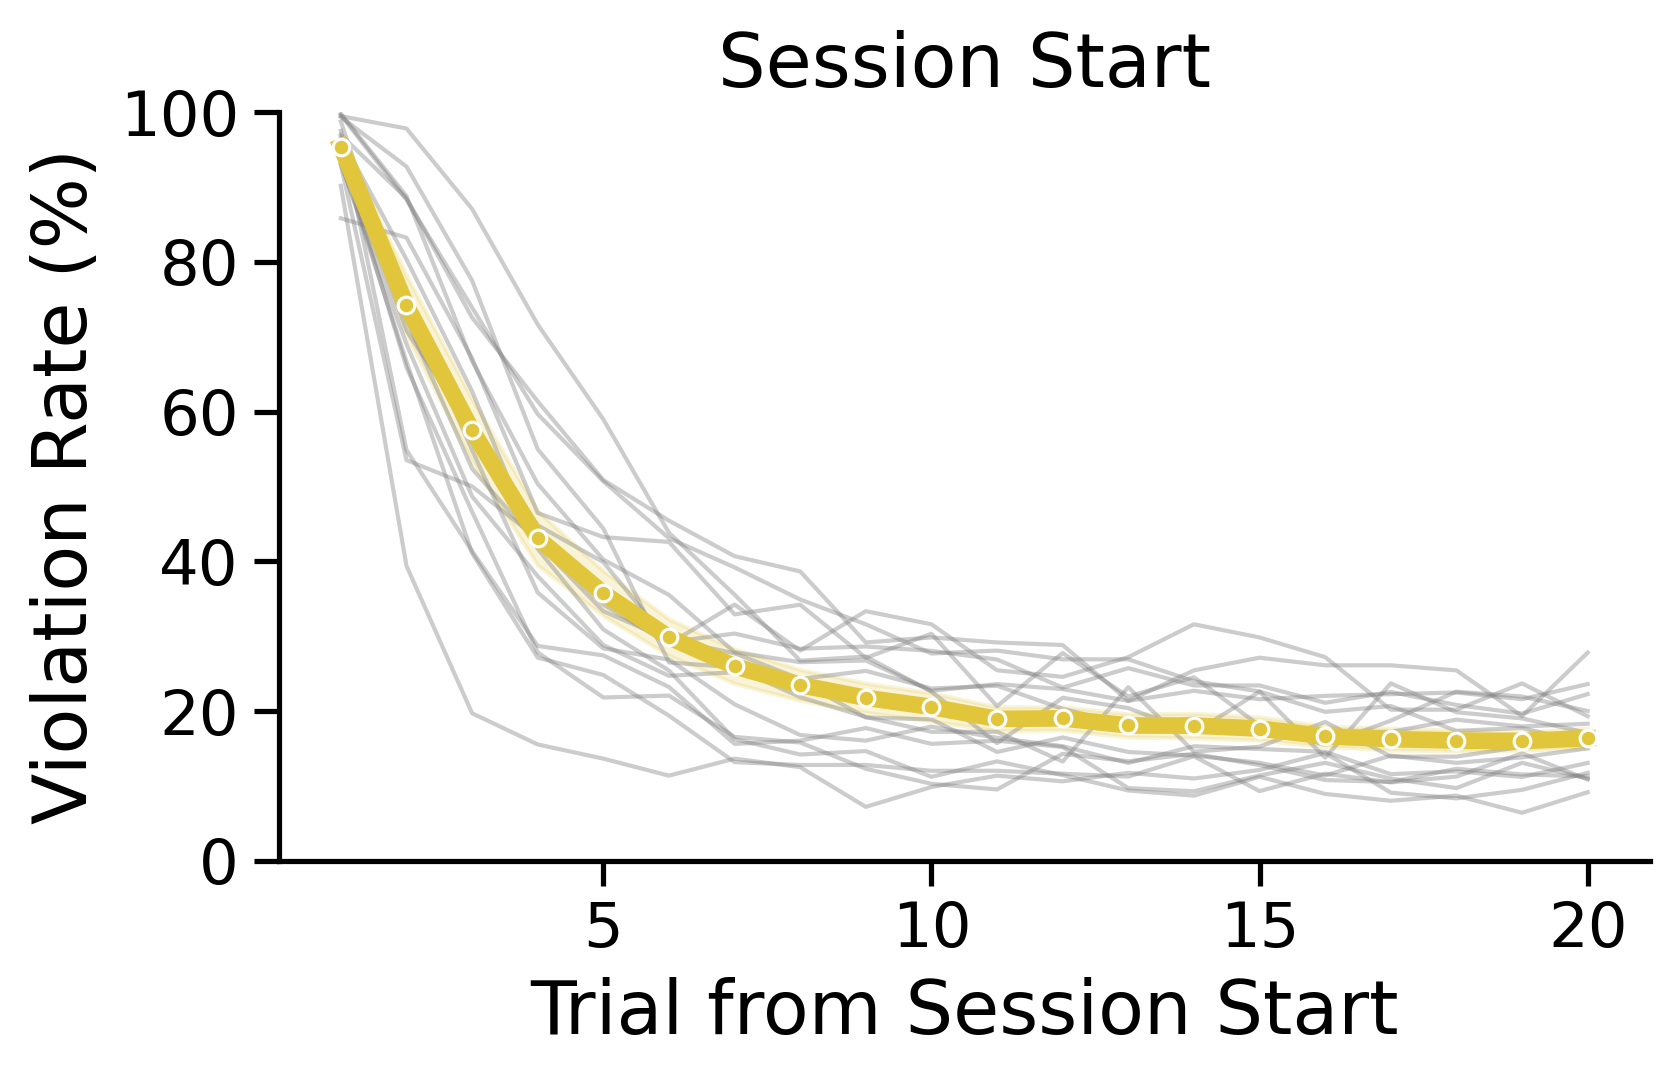

In [5]:
start = edge_rates.query("aligned_to == 'Start'")
fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(
    data=start,
    x="trial_offset",
    y="viol_rate",
    units="animal_id",
    estimator=None,
    color="gray",
    alpha=0.4,
    linewidth=1,
    ax=ax,
)
sns.lineplot(
    data=start,
    x="trial_offset",
    y="viol_rate",
    color=VIOLATION_COLOR,
    errorbar="se",
    linewidth=4,
    ax=ax,
    marker="o",
    markersize=4,
)
ax.set(
    xlabel="Trial from Session Start",
    ylabel="Violation Rate (%)",
    title="Session Start",
    ylim=(0, 100),
)
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "suppS6b_session_start")

## Panel C — Session end


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS6c_session_end.png')

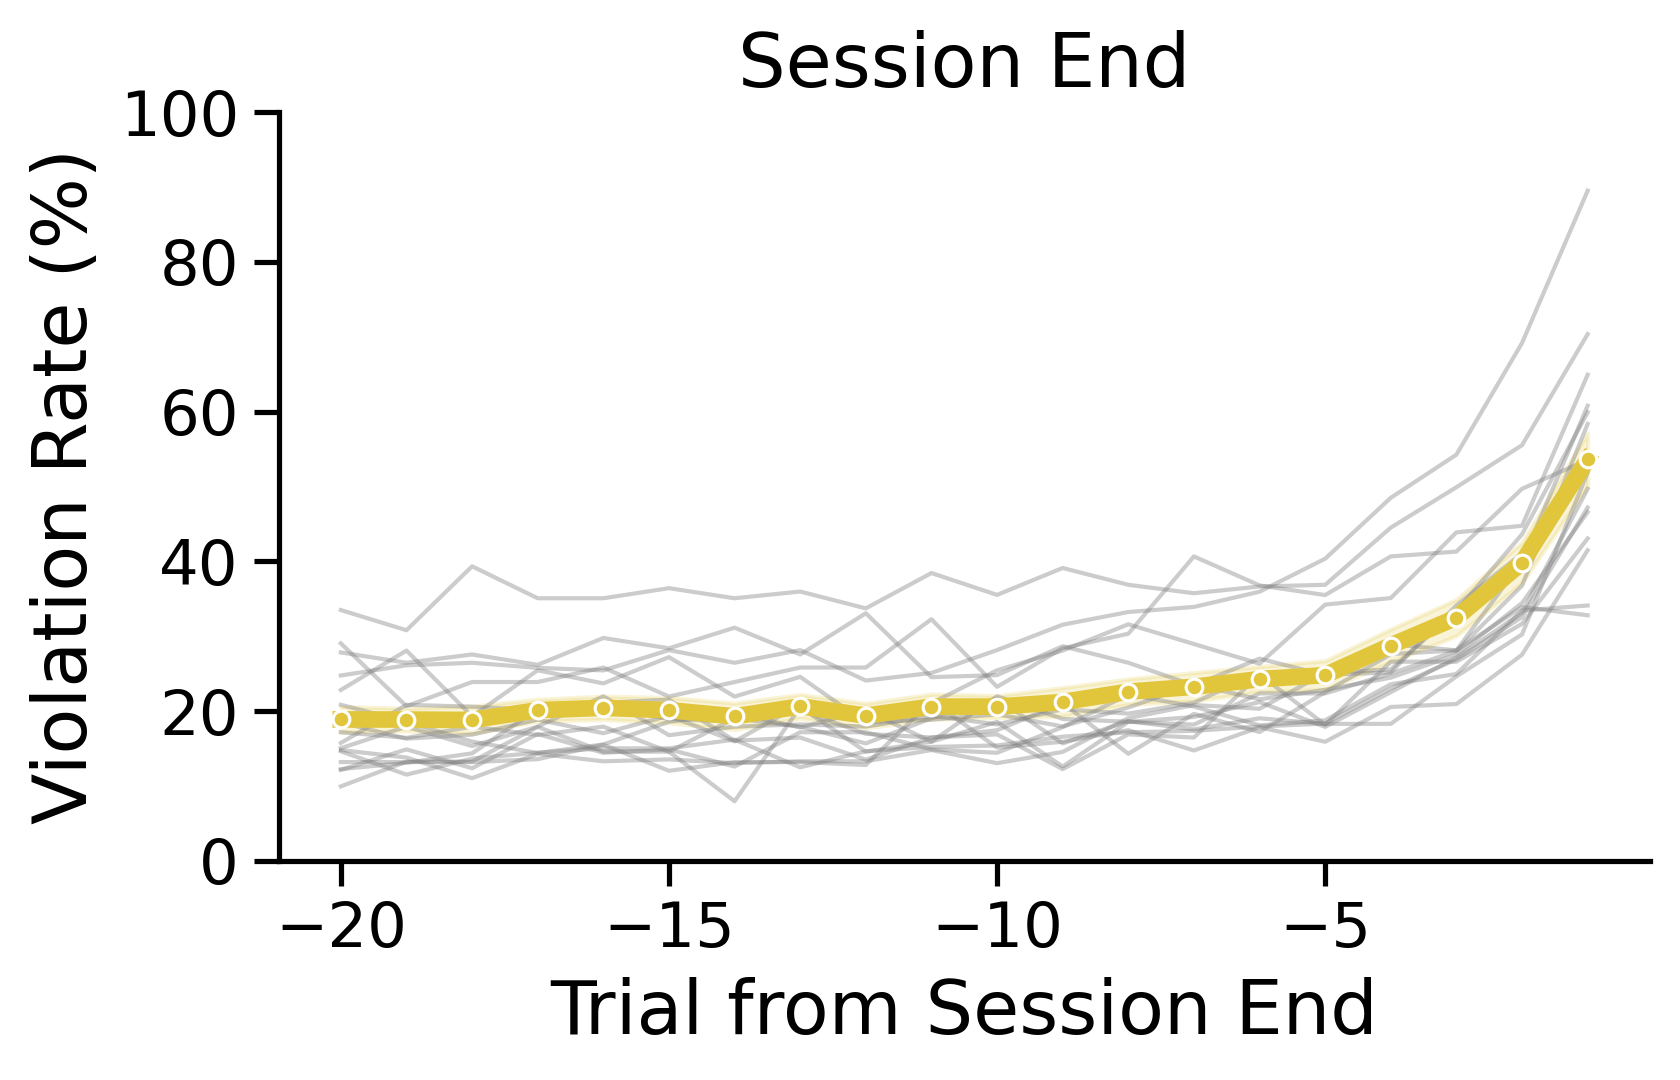

In [6]:
end = edge_rates.query("aligned_to == 'End'")
fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(
    data=end,
    x="trial_offset",
    y="viol_rate",
    units="animal_id",
    estimator=None,
    color="gray",
    alpha=0.4,
    linewidth=1,
    ax=ax,
)
sns.lineplot(
    data=end,
    x="trial_offset",
    y="viol_rate",
    color=VIOLATION_COLOR,
    errorbar="se",
    linewidth=4,
    marker="o",
    markersize=4,
    ax=ax,
)
ax.set(
    xlabel="Trial from Session End",
    ylabel="Violation Rate (%)",
    title="Session End",
    ylim=(0, 100),
)
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "suppS6c_session_end")

## Panel D — Autocorrelation robustness

Same permutation procedure as Figure 3a, with and without the first and last 10 trials of each session. Positive lags only, since the autocorrelation is symmetric by construction and only lags 1–20 are tested. Stars mark lags that remain significant after Bonferroni correction; dots mark non-significant lags.


Significant positive lags (full): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 19]
Significant positive lags (trimmed): [1, 2, 3, 4, 5, 6, 7]
Lag-1 observed: 0.11708833019806736 -> 0.07810140710440845


/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_39254/2144254519.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  is_significant = positive["significant"].fillna(False).astype(bool)
/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_39254/2144254519.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  is_significant = positive["significant"].fillna(False).astype(bool)
/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_39254/2144254519.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprec

,mean_difference_pp,n_animals,n_positive,p_value,t
edge_trials_excluded,10.000000,10.0,10.0,1.000000e+01,10.000000
full,12.139969,16.0,16.0,2.105418e-09,12.645551
trimmed,9.863265,16.0,16.0,1.281986e-08,11.075918


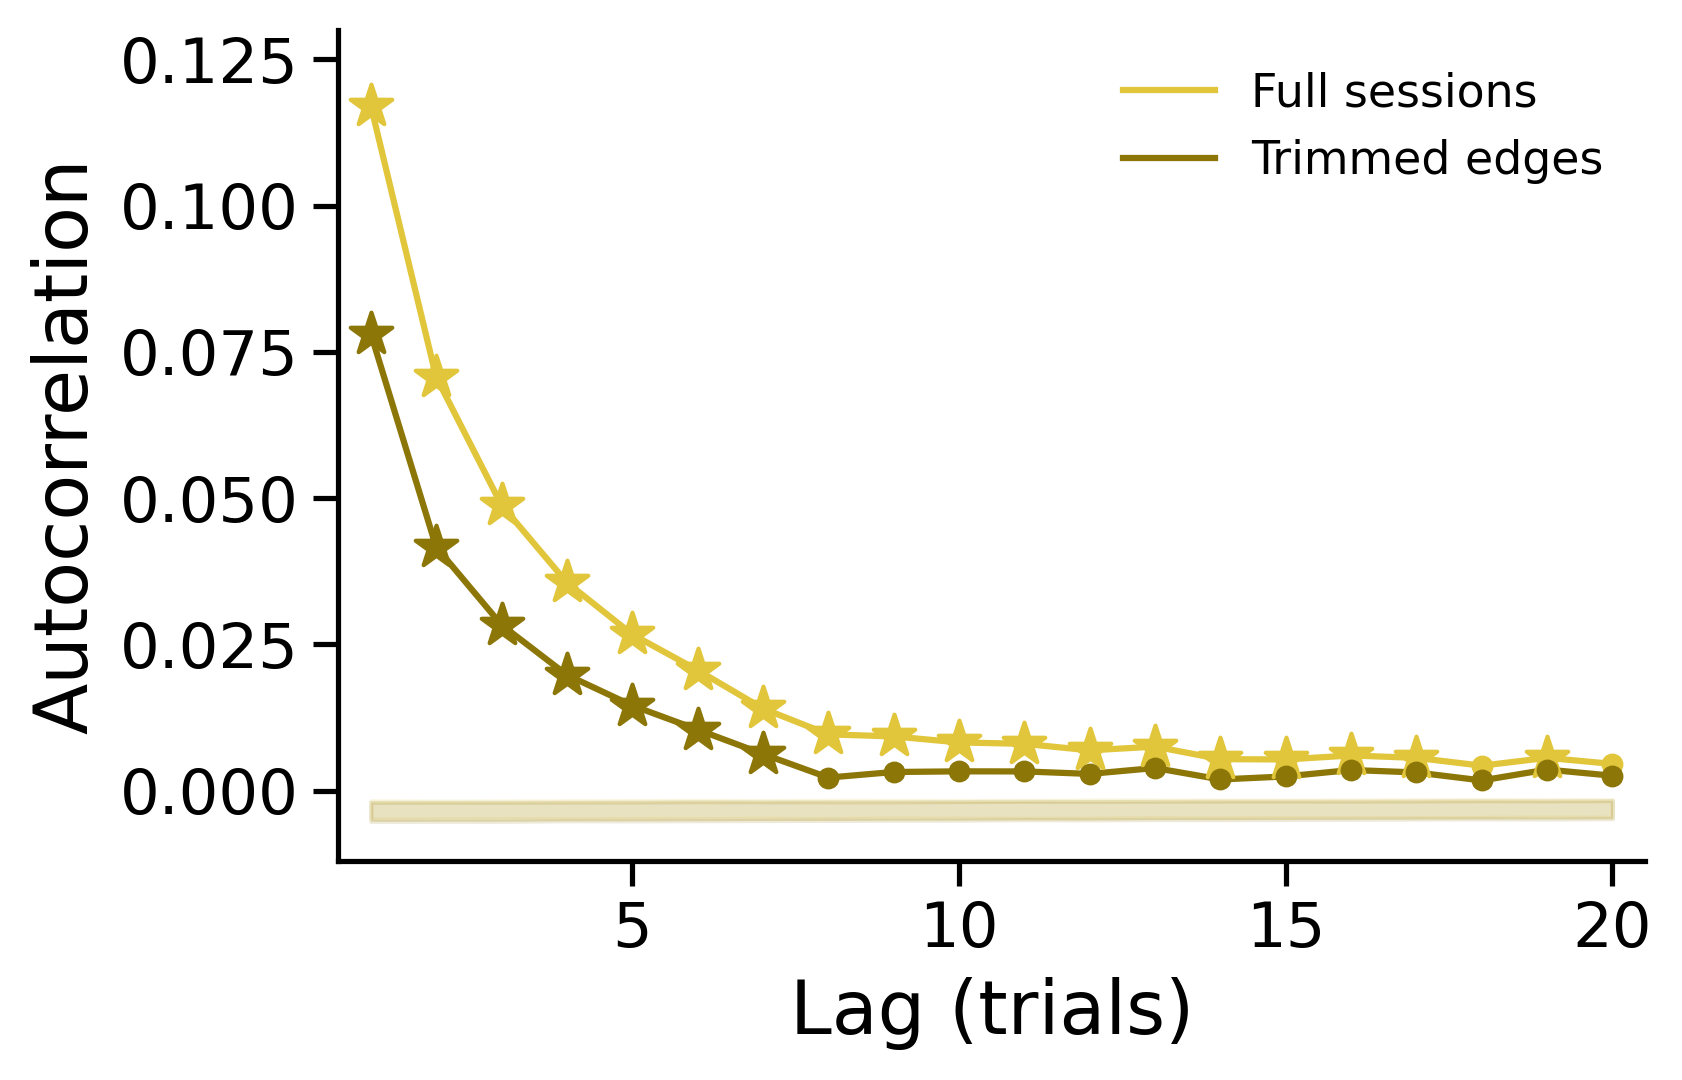

In [8]:
autocorr_full = load_autocorrelation_summary()
autocorr_trim = load_autocorrelation_summary(edges_trimmed=True)
history_robustness = load_history_robustness()

fig, ax = plt.subplots(figsize=(6, 4))
for table, color, label in (
    (autocorr_full, VIOLATION_COLOR, "Full sessions"),
    (autocorr_trim, "#8c7608", "Trimmed edges"),
):
    positive = table.loc[table["lag"] > 0]
    ax.plot(
        positive["lag"],
        positive["observed_mean"],
        color=color,
        label=label,
    )
    ax.fill_between(
        positive["lag"],
        positive["null_ci_lower"],
        positive["null_ci_upper"],
        color=color,
        alpha=0.15,
    )
    is_significant = positive["significant"].fillna(False).astype(bool)
    for mask, marker, size in ((~is_significant, "o", 18), (is_significant, "*", 110)):
        ax.scatter(
            positive.loc[mask, "lag"],
            positive.loc[mask, "observed_mean"],
            color=color,
            marker=marker,
            s=size,
            zorder=3,
        )
ax.set(
    xlabel="Lag (trials)",
    ylabel="Autocorrelation",
    xlim=(0.5, 20.5),
    ylim=(-0.012, 0.13),
)
ax.legend(frameon=False)
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "suppS6d_autocorrelation_robustness")

sig_full = autocorr_full.loc[
    autocorr_full["significant"].fillna(False).astype(
        bool) & (autocorr_full["lag"] > 0),
    "lag",
].astype(int).tolist()
sig_trim = autocorr_trim.loc[
    autocorr_trim["significant"].fillna(False).astype(
        bool) & (autocorr_trim["lag"] > 0),
    "lag",
].astype(int).tolist()
print("Significant positive lags (full):", sig_full)
print("Significant positive lags (trimmed):", sig_trim)
print(
    "Lag-1 observed:",
    float(autocorr_full.loc[autocorr_full.lag == 1, "observed_mean"].iloc[0]),
    "->",
    float(autocorr_trim.loc[autocorr_trim.lag == 1, "observed_mean"].iloc[0]),
)
pd.DataFrame(history_robustness).T